## Analysis on the dark kinases - Positional preference

In [1]:
import pandas as pd

In [2]:
dark_in_screen = ['PHKG1_HUMAN','KKCC1_HUMAN','ADCK1_HUMAN','DYRK4_HUMAN']

In [3]:
blib_screen_tp = pd.read_pickle('./251203_ksi_reduced_df_tp.pkl')
blib_screen_tp = blib_screen_tp.loc[blib_screen_tp['substrate'].apply(lambda s:s[7]!='Y'),:]

In [4]:
st_background = blib_screen_tp[['substrate']].drop_duplicates()
st_background.to_csv('260107_dark_kinase_substrate_background.csv')

In [5]:
substrates_background = pd.read_pickle('./substrates_background_12345.pkl')
blib_screen_tp_mapped = pd.merge(substrates_background,blib_screen_tp,left_on = 'substrate_seq_15aa',right_on = 'substrate')


In [6]:
blib_screen_tp_mapped['substrate_seq_15aa'].drop_duplicates().shape

(1997,)

In [7]:
blib_screen_tp_mapped['substrate_x'].drop_duplicates().shape

(4358,)

In [8]:
blib_screen_tp_mapped['substrate_x'].drop_duplicates().to_csv('./dark_kinase_in/260107_dark_kinase_substrate_background_acc.csv')

In [9]:
## OPTIONAL thresholding removing more promiscuous substrates
dat_all_blib_fp = blib_screen_tp
total_kinases = dat_all_blib_fp.groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
pos_kinases = dat_all_blib_fp.loc[dat_all_blib_fp['positive'],:].groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
fp_stats = pd.merge(pos_kinases,total_kinases,on = 'substrate')
fp_stats.columns = ['substrate','pos_kinase','tot_kinase']
fp_stats['promiscuous_score'] = fp_stats['pos_kinase']/fp_stats['tot_kinase']
fp_stats = fp_stats.loc[(fp_stats['promiscuous_score']<0.3)&(fp_stats['tot_kinase']>5),:]
blib_screen_tp = blib_screen_tp.loc[blib_screen_tp['substrate'].isin(fp_stats['substrate']),:]

In [10]:
blib_screen_tp_dark = blib_screen_tp.loc[blib_screen_tp['kinase'].isin(dark_in_screen),:]

In [11]:
blib_screen_tp_dark.loc[blib_screen_tp_dark['true_positive'],:].to_csv('./dark_kinase_in/260107_dark_kinase_ksi_hits.csv')

In [12]:
hits_df = blib_screen_tp_dark.loc[blib_screen_tp_dark['true_positive'],:]
hits_df.columns = ['substrate_seq_15aa', 'kinase', 'positive', 'paabd_hit', 'paabd_all', 'n_paabd',
       'hit_count', 'binding_max', 'binding_best_hit', 'lfsr_min',
       'lfsr_best_hit', 'fp_sub', 'true_positive']
background_df = st_background
print(f"Loaded {len(hits_df)} true positive hits")
print(f"Loaded {len(background_df)} background substrates (position-matched 15-mers)")

Loaded 293 true positive hits
Loaded 1997 background substrates (position-matched 15-mers)


In [13]:
hits_df.groupby('kinase').count()

,substrate_seq_15aa,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
kinase,,,,,,,,,,,,
ADCK1_HUMAN,22,22,22,22,22,22,22,22,22,22,22,22
KKCC1_HUMAN,208,208,208,208,208,208,208,208,208,208,208,208
PHKG1_HUMAN,63,63,63,63,63,63,63,63,63,63,63,63


In [14]:
from information_content_calculator import *
from plotnine import *

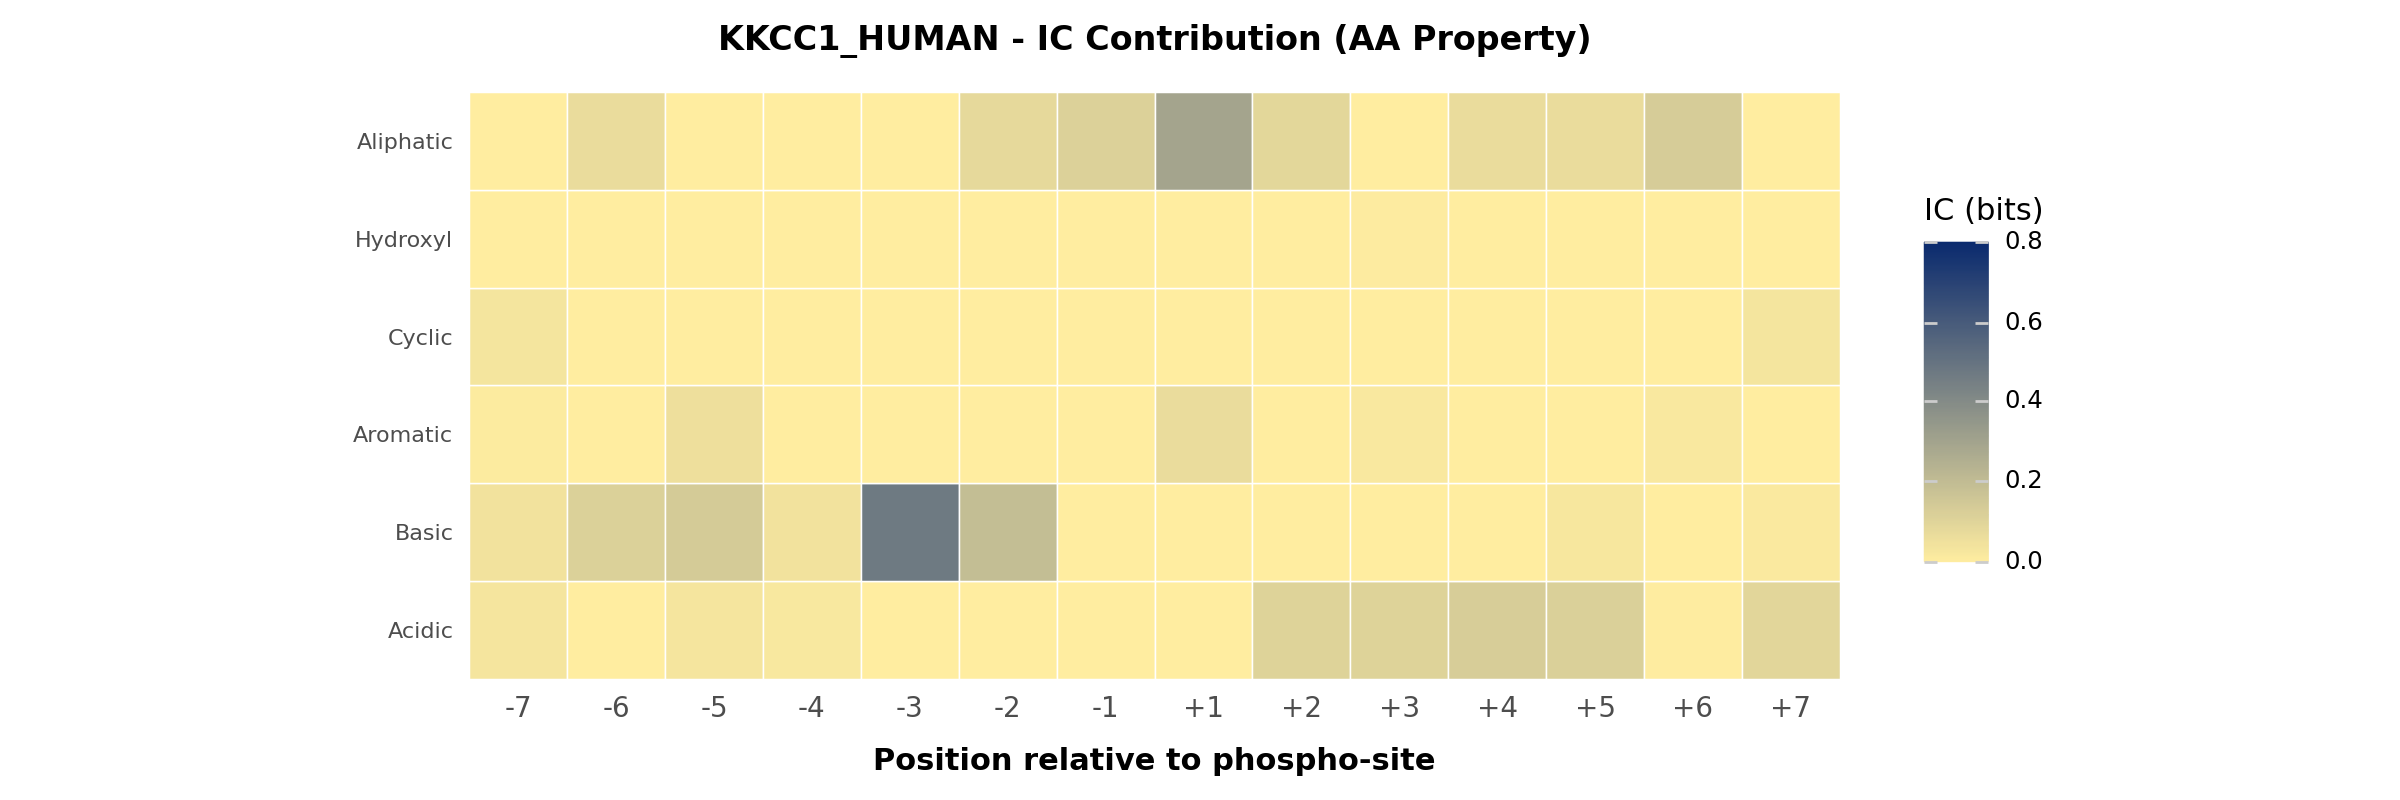

,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7
Acidic,0.030561,0.000000,0.030561,0.020644,0.000000,0.000000,0.0,0.000000,0.000000,0.107305,0.107305,0.131382,0.119232,0.001674,0.095607
Basic,0.045217,0.114671,0.139998,0.045217,0.474621,0.193563,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.024482,0.000000,0.014615
Aromatic,0.009636,0.000000,0.056503,0.000000,0.000000,0.000000,0.0,0.000000,0.069989,0.000000,0.020173,0.000000,0.000000,0.020173,0.000000
Cyclic,0.034219,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.034219
Hydroxyl,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,2.048536,0.000000,0.000000,0.007444,0.000000,0.000000,0.000000,0.000000


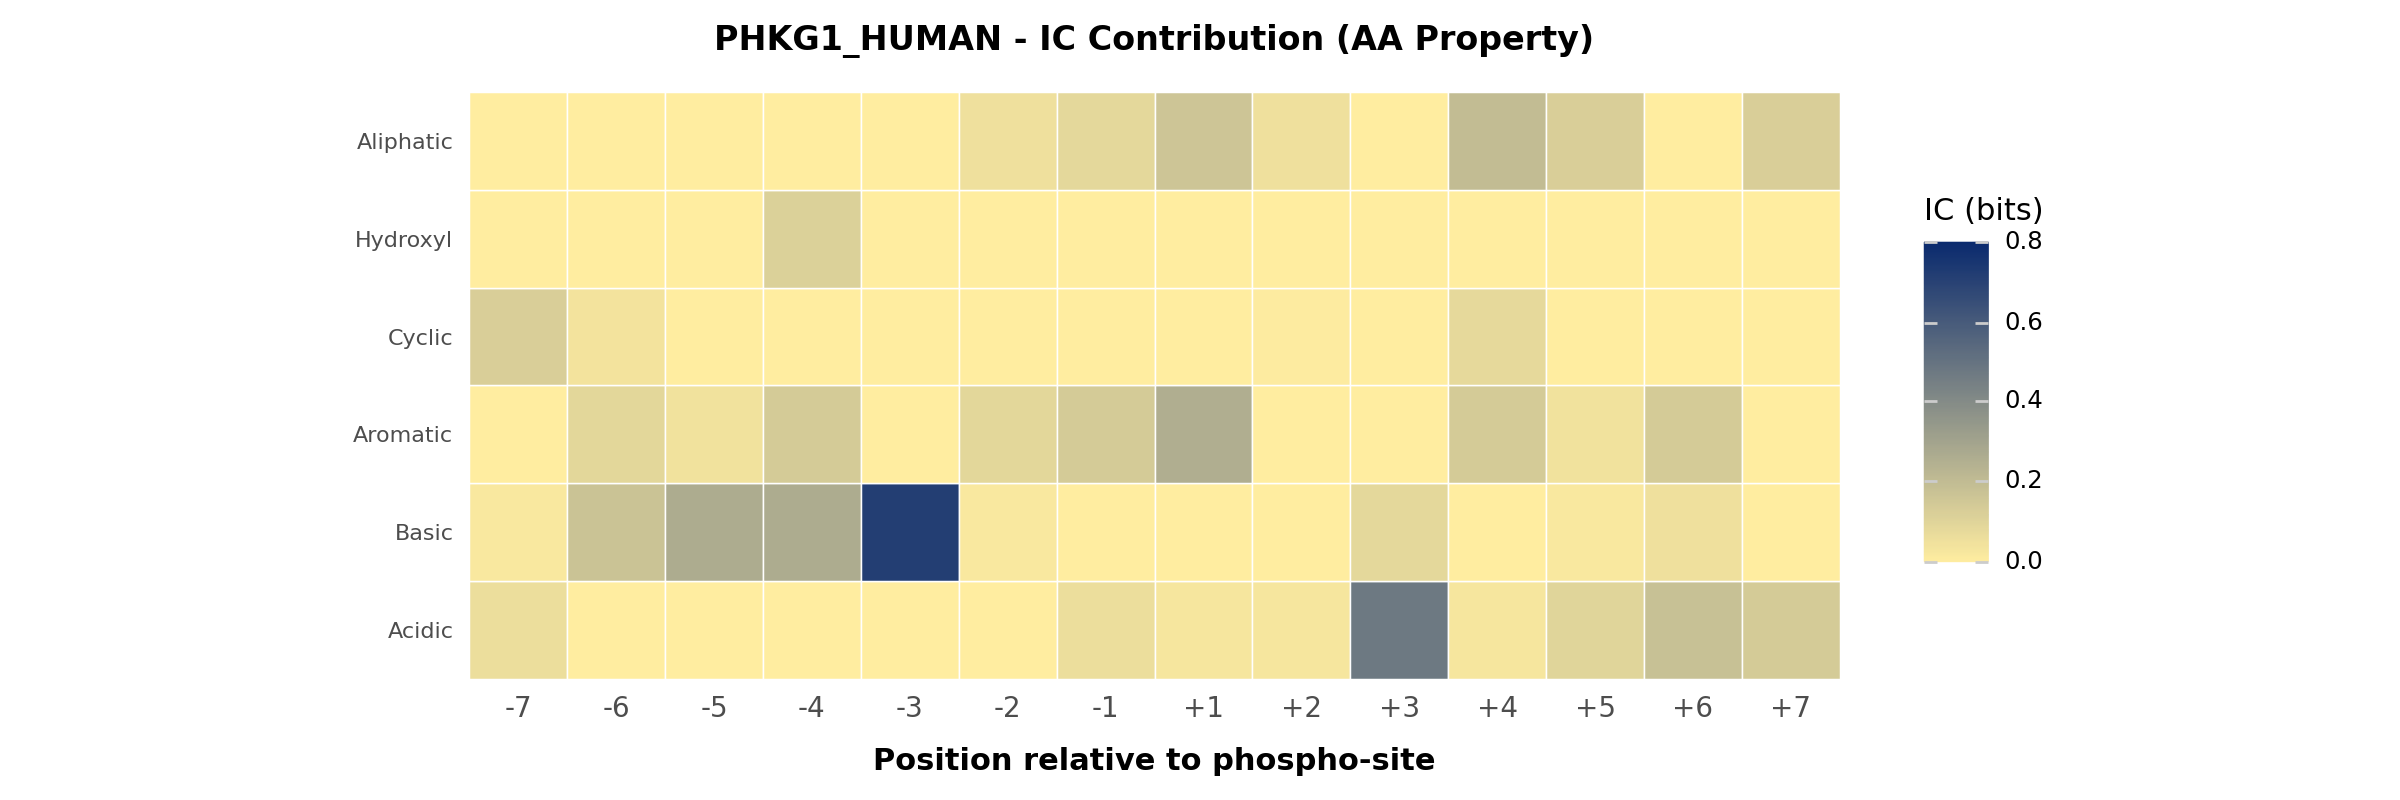

,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7
Acidic,0.064207,0.000000,0.000000,0.000000,0.000000,0.000000,0.064207,0.000000,0.029724,0.029724,0.476114,0.029724,0.101427,0.183196,0.141154
Basic,0.017866,0.173039,0.266743,0.266743,0.718036,0.017866,0.000000,0.000000,0.000000,0.000000,0.089400,0.000000,0.017866,0.051960,0.000000
Aromatic,0.000000,0.090737,0.045762,0.141763,0.000000,0.090737,0.141763,0.000000,0.258191,0.000000,0.000000,0.141763,0.045762,0.141763,0.000000
Cyclic,0.126012,0.039443,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.004727,0.000000,0.080211,0.000000,0.000000,0.000000
Hydroxyl,0.000000,0.000000,0.000000,0.115770,0.000000,0.000000,0.000000,2.048536,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


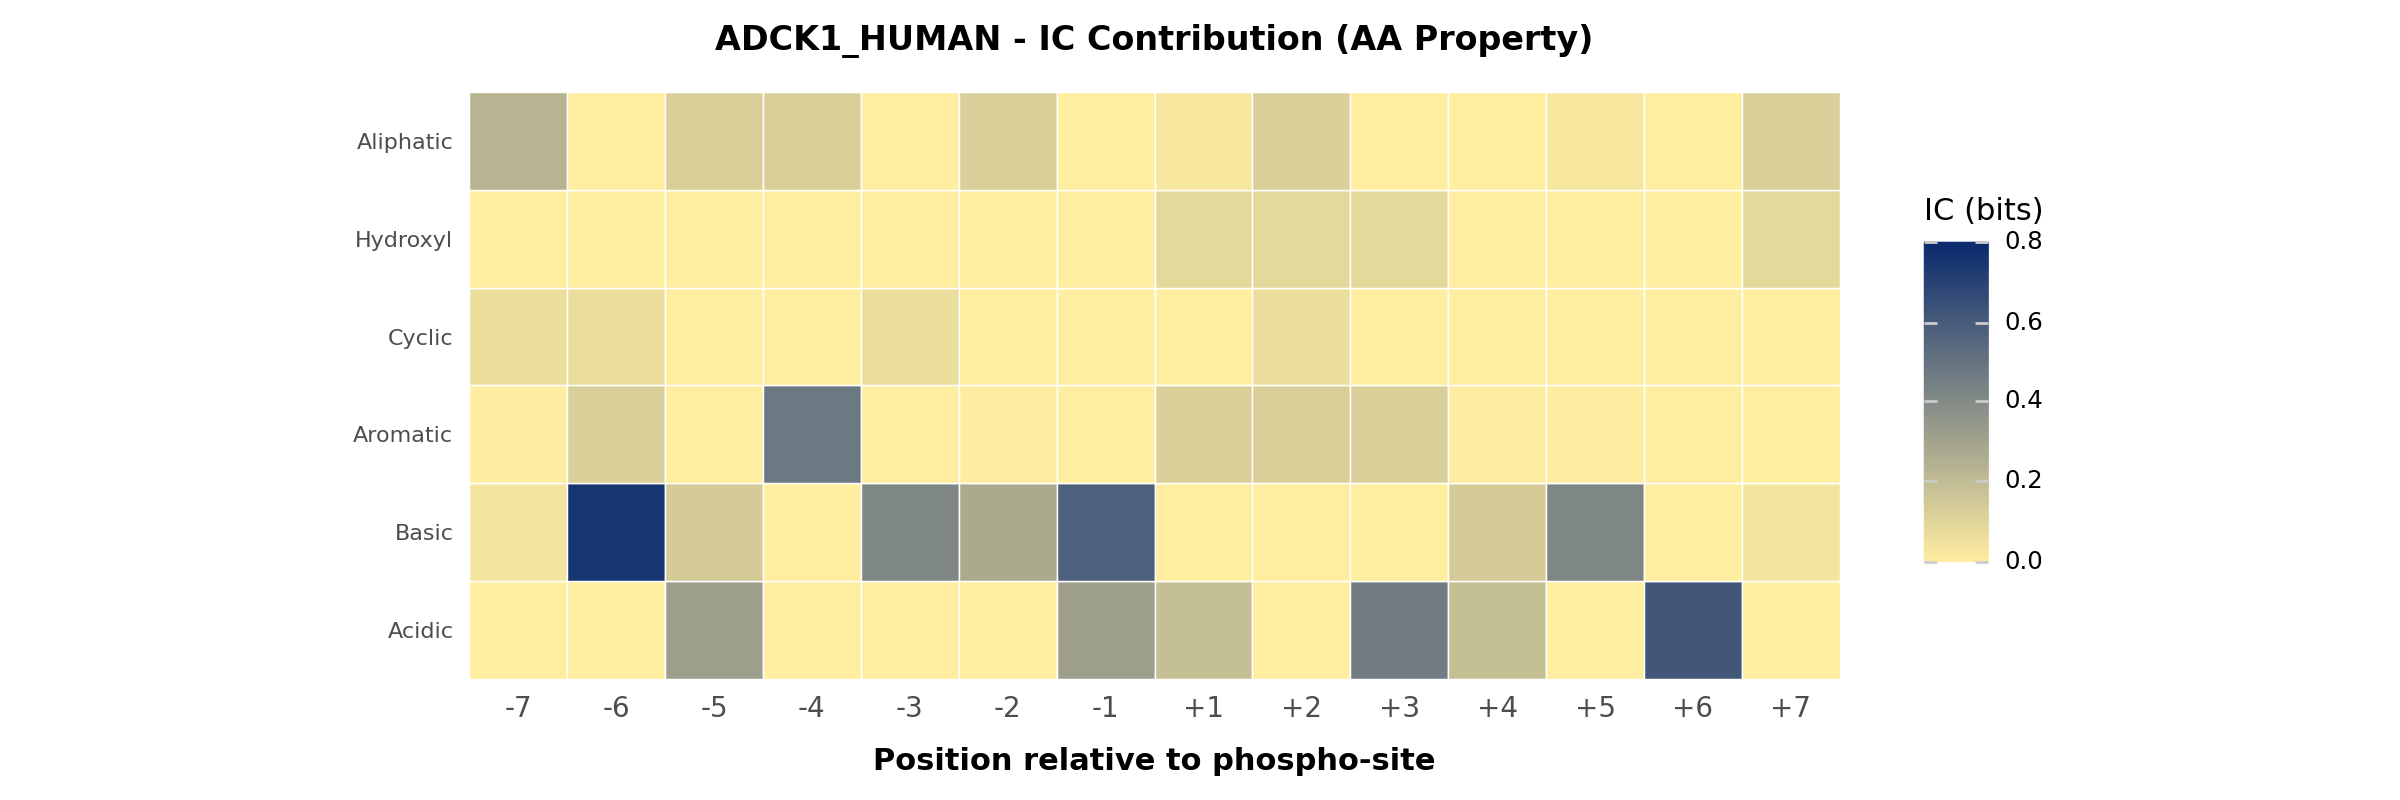

,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7
Acidic,0.000000,0.000000,0.318779,0.000000,0.000000,0.000000,0.318779,0.000000,0.188286,0.000000,0.463482,0.188286,0.000000,0.620351,0.000000
Basic,0.033469,0.755150,0.142281,0.000000,0.419878,0.272536,0.581431,0.000000,0.000000,0.000000,0.000000,0.142281,0.419878,0.000000,0.033469
Aromatic,0.002744,0.123135,0.000000,0.481563,0.000000,0.002744,0.000000,0.000000,0.123135,0.123135,0.123135,0.002744,0.002744,0.000000,0.000000
Cyclic,0.065203,0.065203,0.000000,0.000000,0.065203,0.000000,0.000000,0.000000,0.000000,0.065203,0.000000,0.000000,0.000000,0.000000,0.000000
Hydroxyl,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.048536,0.083236,0.083236,0.083236,0.000000,0.000000,0.000000,0.083236


In [15]:
hits_df = hits_df[hits_df["true_positive"] == True].copy()
background_sequences = background_df["substrate"].values

for kinase in hits_df["kinase"].unique():
    kinase_hits = hits_df.loc[hits_df["kinase"] == kinase, "substrate_seq_15aa"].values

    p1_aa, df_aa = make_ic_panel1_plot_and_df(
        kinase_hits, background_sequences,
        kinase_name=kinase, level="amino_acid",
        exclude_phospho_site=True,
        block_plus1=True,  # blocks +1 P at AA level
    )

    p1_prop, df_prop = make_ic_panel1_plot_and_df(
        kinase_hits, background_sequences,
        kinase_name=kinase, level="property",
        exclude_phospho_site=True,
        block_plus1=True,  # blocks +1 Cyclic at property level via AA_TO_PROPERTY
    )

    # You can save if you want:
    
    p1_aa = p1_aa +  theme(
            figure_size=(12, 8))

    p1_aa.save(f"./dark_kinase_out/IC_heatmap_aa_{kinase}.png", dpi=300)
    p1_prop.save(f"./dark_kinase_out/IC_heatmap_prop_{kinase}.png", dpi=300)
    df_aa.to_csv(f"./dark_kinase_out/IC_matrix_aa_{kinase}.csv")
    df_prop.to_csv(f"./dark_kinase_out/IC_matrix_prop_{kinase}.csv")
    
    # display(p1_aa)
    display(p1_prop)
    display(df_prop.head())


In [ ]:
kinase_map = {'Q86TW2':'ADCK1_HUMAN',
             'Q8N5S9':'KKCC1_HUMAN',
             'Q16816':'PHKG1_HUMAN'}

In [ ]:
label_dat = pd.read_csv('./pairs_aug_v2.csv').iloc[:,1:]
label_dat = label_dat.loc[label_dat['kinase'].isin((['Q86TW2','Q8N5S9','Q16816']))&(label_dat['label']==1),:].drop_duplicates().sort_values('kinase')
label_dat['kinase_name'] = label_dat['kinase'].apply(lambda s: kinase_map[s])

In [ ]:
label_dat = label_dat.loc[:,['kinase_name','substrate_seq_15aa']]
label_dat.columns = ['kinase','substrate_seq_15aa']

In [ ]:
pd.merge(blib_screen_tp_dark,label_dat,left_on =['kinase','substrate'],right_on =['kinase','substrate_seq_15aa']).drop_duplicates()